# ADORA2A Retrospective Virtual Screening & Curation Audit

Interactive, reproducible walkthrough of the four phases of our case study on the human Adenosine $A_{2A}$ receptor (`ADORA2A`, UniProt `P29274`, `CHEMBL251`):

1. **Structural Audit (GPCRdb + RCSB PDB):** why selecting `4EIY` (1.80 Å, 100% wild-type pocket) avoids the pocket-mutation trap present in nominally higher-resolution `StaR2` structures (`5NM4` at 1.70 Å and `5IU4` at 1.72 Å carry `T88A` and `S277A` inside the orthosteric pocket).
2. **Bioactivity Curation & 1D Bias Control:** strict separation of equilibrium binding ($K_i$) from functional $IC_{50}$ assays, contextual PAINS/Brenk structural alert auditing, and multivariate 7D decoy matching (including `TPSA`).
3. **Four-Level Retrospective Benchmark & Honest Metrics:** quantitative contrast between misleading *Accuracy* (~97.5%) / global `ROC-AUC` and early-enrichment metrics (**EF1%**, **EF5%**, **BEDROC $\alpha=20$**, **PR-AUC**), **Murcko scaffold-split** generalization, and empirical proof that **screening score $\neq$ experimental binding affinity ($pK_i$)**.

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROC = ROOT / "data" / "processed"
FIGS = ROOT / "reports" / "figures"

summary = json.loads((PROC / "audit_summary.json").read_text(encoding="utf-8"))
print(f"Total ADORA2A structures audited: {summary['n_structures_audited']}")
print("Breakdown by conformational state:", summary["structures_by_state"])

Total ADORA2A structures audited: 188
Breakdown by conformational state: {'Inactive': 172, 'Active': 15, 'Intermediate': 1}


## 1. Phase 1 · GPCR Structural Audit (188 PDB Entries)

We inspect the highest-resolution inactive and active structures, verifying at the atomic coordinate level that `StaR2` constructs (`5NM4`, `5IU4`) mutate `Thr88` and `Ser277` to `Ala` inside the orthosteric pocket, whereas `4EIY` (1.80 Å) preserves a 100% wild-type human 7TM pocket and resolves the allosteric $\text{Na}^+$ ion.

,pdb_code,state,method,resolution,ligand_names,has_allosteric_na,mutation_count,construct_class
15,5NM4,Inactive,X-ray diffraction,1.70,ZM-241385,True,9,Thermostabilized StaR2 (pocket T88A/S277A risk)
16,5IU4,Inactive,X-ray diffraction,1.72,ZM-241385,True,11,Thermostabilized StaR2 (pocket T88A/S277A risk)
17,9H37,Inactive,X-ray diffraction,1.72,Compound 9,True,0,WT-7TM + ICL3-BRIL
18,9H2X,Inactive,X-ray diffraction,1.75,Compound 7,True,0,WT-7TM + ICL3-BRIL
19,4EIY,Inactive,X-ray diffraction,1.80,ZM-241385,True,3,WT-7TM + ICL3-BRIL
20,6LPJ,Inactive,X-ray diffraction,1.80,ZM-241385,True,3,WT-7TM + ICL3-BRIL
21,6LPK,Inactive,X-ray diffraction,1.80,ZM-241385,True,3,WT-7TM + ICL3-BRIL
22,7IO5,Inactive,X-ray diffraction,1.84,FU12-45; theophylline,True,8,Thermostabilized StaR2 (pocket T88A/S277A risk)


,pdb_code,state,method,resolution,ligand_names,has_allosteric_na,mutation_count,construct_class
0,2YDV,Active,X-ray diffraction,2.60,NECA,False,5,Thermostabilized GL31/StaR
1,4UG2,Active,X-ray diffraction,2.60,CGS 21680,False,5,Thermostabilized GL31/StaR
2,4UHR,Active,X-ray diffraction,2.60,CGS 21680,False,5,Thermostabilized GL31/StaR
3,5WF5,Active,X-ray diffraction,2.60,"UK-432,097",False,5,Thermostabilized GL31/StaR
4,9EE8,Active,Electron microscopy,2.63,adenosine,False,2,Active Gs/mini-Gs signaling complex
5,3QAK,Active,X-ray diffraction,2.71,"UK-432,097",False,2,WT-7TM + ICL3-T4L


Orthosteric pocket mutations caught in 5IU4: {'88': ['THR', 'ALA'], '277': ['SER', 'ALA']}


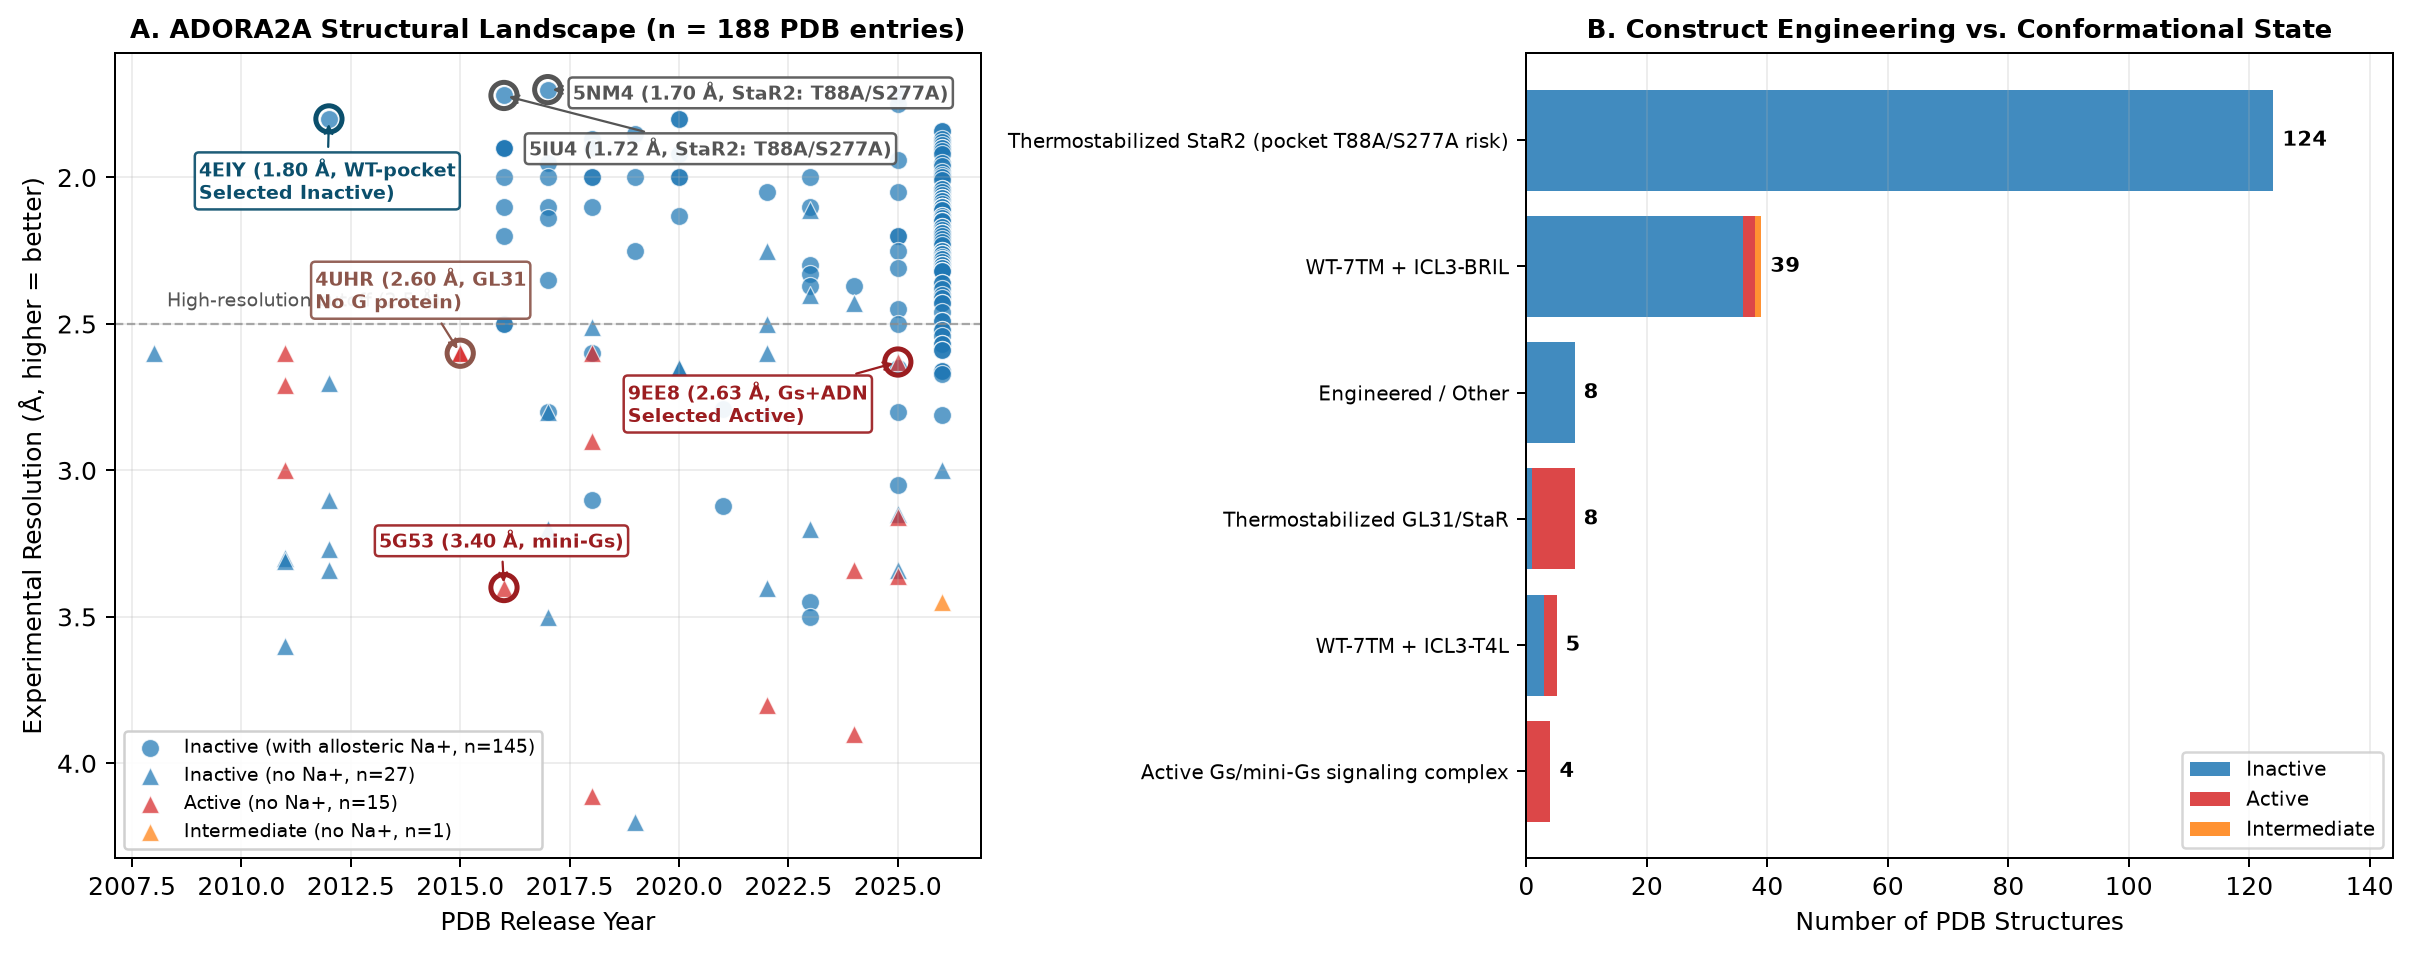

In [2]:
struct_df = pd.read_csv(PROC / "adora2a_structures_audit.csv")
cols = [
    "pdb_code",
    "state",
    "method",
    "resolution",
    "ligand_names",
    "has_allosteric_na",
    "mutation_count",
    "construct_class",
]
display(struct_df[struct_df["state"] == "Inactive"].sort_values("resolution")[cols].head(8))
display(struct_df[struct_df["state"] == "Active"].sort_values("resolution")[cols].head(6))
print("Orthosteric pocket mutations caught in 5IU4:", summary["pocket_checks"]["5IU4_mutations"])
display(Image(filename=str(FIGS / "structure_audit_resolution_state.png")))

## 2. Phase 2 · Provenance-Preserving Curation, Contextual Alerts & 1D Bias Gate

- **Curation waterfall:** filter `confidence_score >= 8`, exact `'='` relation, normalized `nM` units, and strictly isolate equilibrium binding `Ki_B` from `IC50` cohorts.
- **Contextual PAINS/Brenk audit:** verify approved drugs and clinical candidates before applying blind structural filters.
- **1D Decoy-Bias *Go/No-Go* Gate:** a 1D classifier (`LogisticRegression` and `RandomForest`) trained solely on `[MW, cLogP, TPSA, HBD, HBA, RotBonds, FormalCharge]` exposes severe leakage on random ChEMBL decoys (`AUC = 0.81 / 0.78`), dropping well below `0.60` (`0.48 / 0.35`) after joint 7D matching.

,Curation Step,Records / Compounds
0,01_raw_ki_ic50_records,12105
1,02_confidence_ge_8,12105
2,03_exact_relation_eq,8349
3,04_valid_nm_and_smiles,8347
4,05_no_validity_warning,8167
5,06_rdkit_standardized_organic,8150
6,07_cohort_Ki_B_measurements,5901
7,07b_cohort_IC50_B_measurements,1224
8,07c_cohort_IC50_F_measurements,496
9,08_unique_inchikey_Ki_B,4972


,name,clinical_status,has_pains,has_brenk,brenk_alerts
0,ZM241385,Preclinical gold-standard probe,False,False,NaN
1,Istradefylline,Approved (Phase 4),False,False,NaN
2,Caffeine,Approved (Phase 4),False,False,NaN
3,Theophylline,Approved (Phase 4),False,False,NaN
4,Preladenant,Phase 3,False,False,NaN
5,Vipadenant,Phase 2,False,True,aniline
6,Tozadenant,Phase 3,True,False,NaN
7,Imaradenant,Phase 2,False,True,2-halo_pyridine
8,Adenosine,Approved (Phase 4),False,False,NaN
9,NECA,Preclinical probe,False,False,NaN


1D Bias Go/No-Go Audit: {
  "unmatched_logistic_auc": 0.8142,
  "unmatched_rf_auc": 0.7834,
  "matched_logistic_auc": 0.4841,
  "matched_rf_auc": 0.3464,
  "passed_go_nogo": true
}


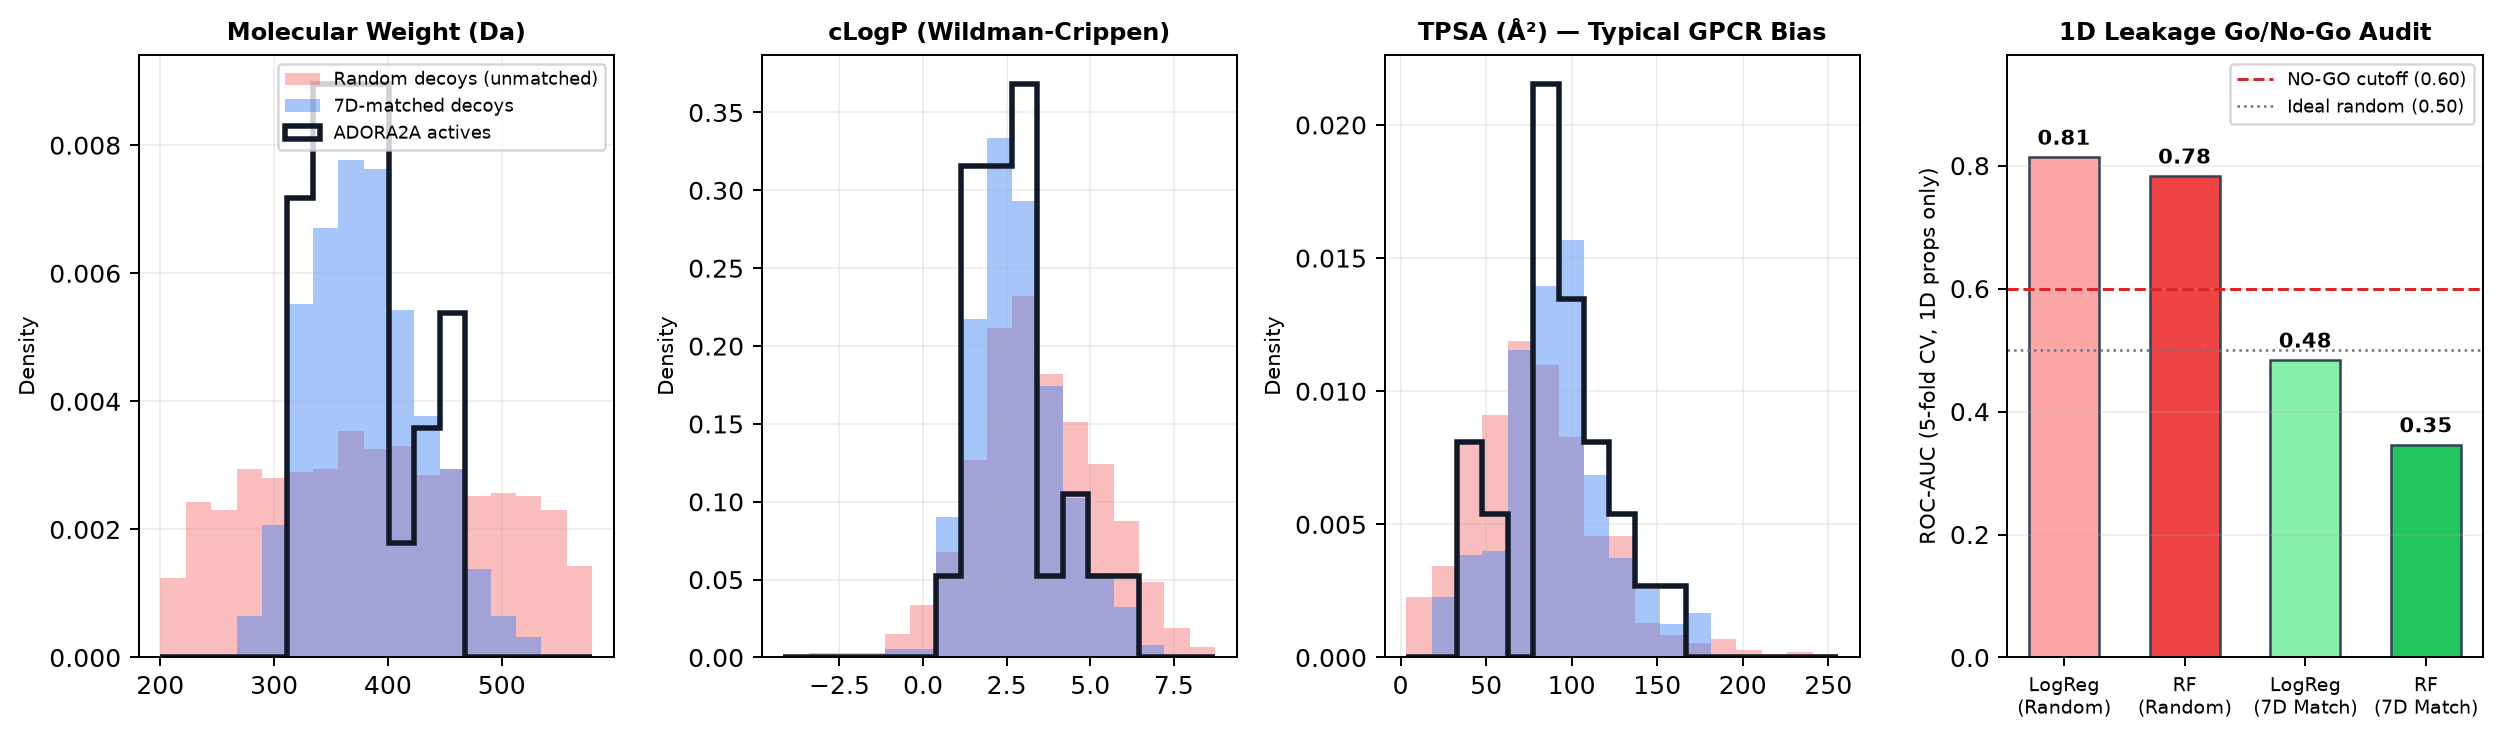

In [3]:
waterfall_df = pd.DataFrame(
    list(summary["curation_waterfall"].items()),
    columns=["Curation Step", "Records / Compounds"],
)
display(waterfall_df)

alerts_df = pd.read_csv(PROC / "reference_ligands_alerts_audit.csv")
display(alerts_df[["name", "clinical_status", "has_pains", "has_brenk", "brenk_alerts"]])

print("1D Bias Go/No-Go Audit:", json.dumps(summary["bias_audit"], indent=2))
display(Image(filename=str(FIGS / "decoy_property_matching_audit.png")))

## 3. Phase 3 · Four-Level Retrospective Benchmark & Honest Metrics

We compare across the exact same **1,000 compounds** (25 scaffold-diverse potent actives + 975 7D-matched decoys, **2.5% hit rate**):
1. **1D Negative Control** (out-of-fold Random Forest on 7 physicochemical descriptors).
2. **2D ECFP4 Similarity** to co-crystallized `ZM241385` (plus strict non-analogue subset and experimental **Murcko scaffold split**).
3. **3D Shape & Pharmacophore** (`ETKDGv3` + `USRCAT` + `CrippenO3A Shape Tanimoto` to `ZMA`).
4. **Structure-Based Docking** (**AutoDock Vina v1.2.7** into the pH 7.4 wild-type pocket of `4EIY`).

,method,ef1,ef5,bedroc_20,roc_auc,pr_auc,accuracy_top1pct,naive_all_inactive_accuracy
0,1D Physicochemical (Control),0.0,0.0,0.026,0.346,0.019,0.965,0.975
1,2D ECFP4 (vs ZM241385),36.0,9.6,0.519,0.725,0.433,0.983,0.975
2,3D Shape + USRCAT (vs ZMA),8.0,6.4,0.355,0.722,0.166,0.969,0.975
3,3D Docking (AutoDock Vina · 4EIY),0.0,0.8,0.063,0.584,0.033,0.965,0.975



Strict scaffold-hop subset (excluding close analogues with ECFP4 >= 0.35 to ZM241385):


,method,n_actives,ef1,ef5,bedroc_20,roc_auc,pr_auc
0,"2D ECFP4 (no ZMA analogues, ECFP4<0.35)",21,23.714,7.589,0.402,0.673,0.303
1,"AutoDock Vina (no ZMA analogues, ECFP4<0.35)",21,0.000,0.949,0.072,0.625,0.032



Supervised 2D generalization on experimental CHEMBL251 (Random Split vs Murcko Scaffold Split):


,method,ef1,ef5,bedroc_20,roc_auc,pr_auc
0,2D ECFP4 ML experimental (Random Split),8.142,8.239,0.947,0.983,0.917
1,2D ECFP4 ML experimental (Murcko Scaffold Split),8.142,7.827,0.914,0.979,0.880


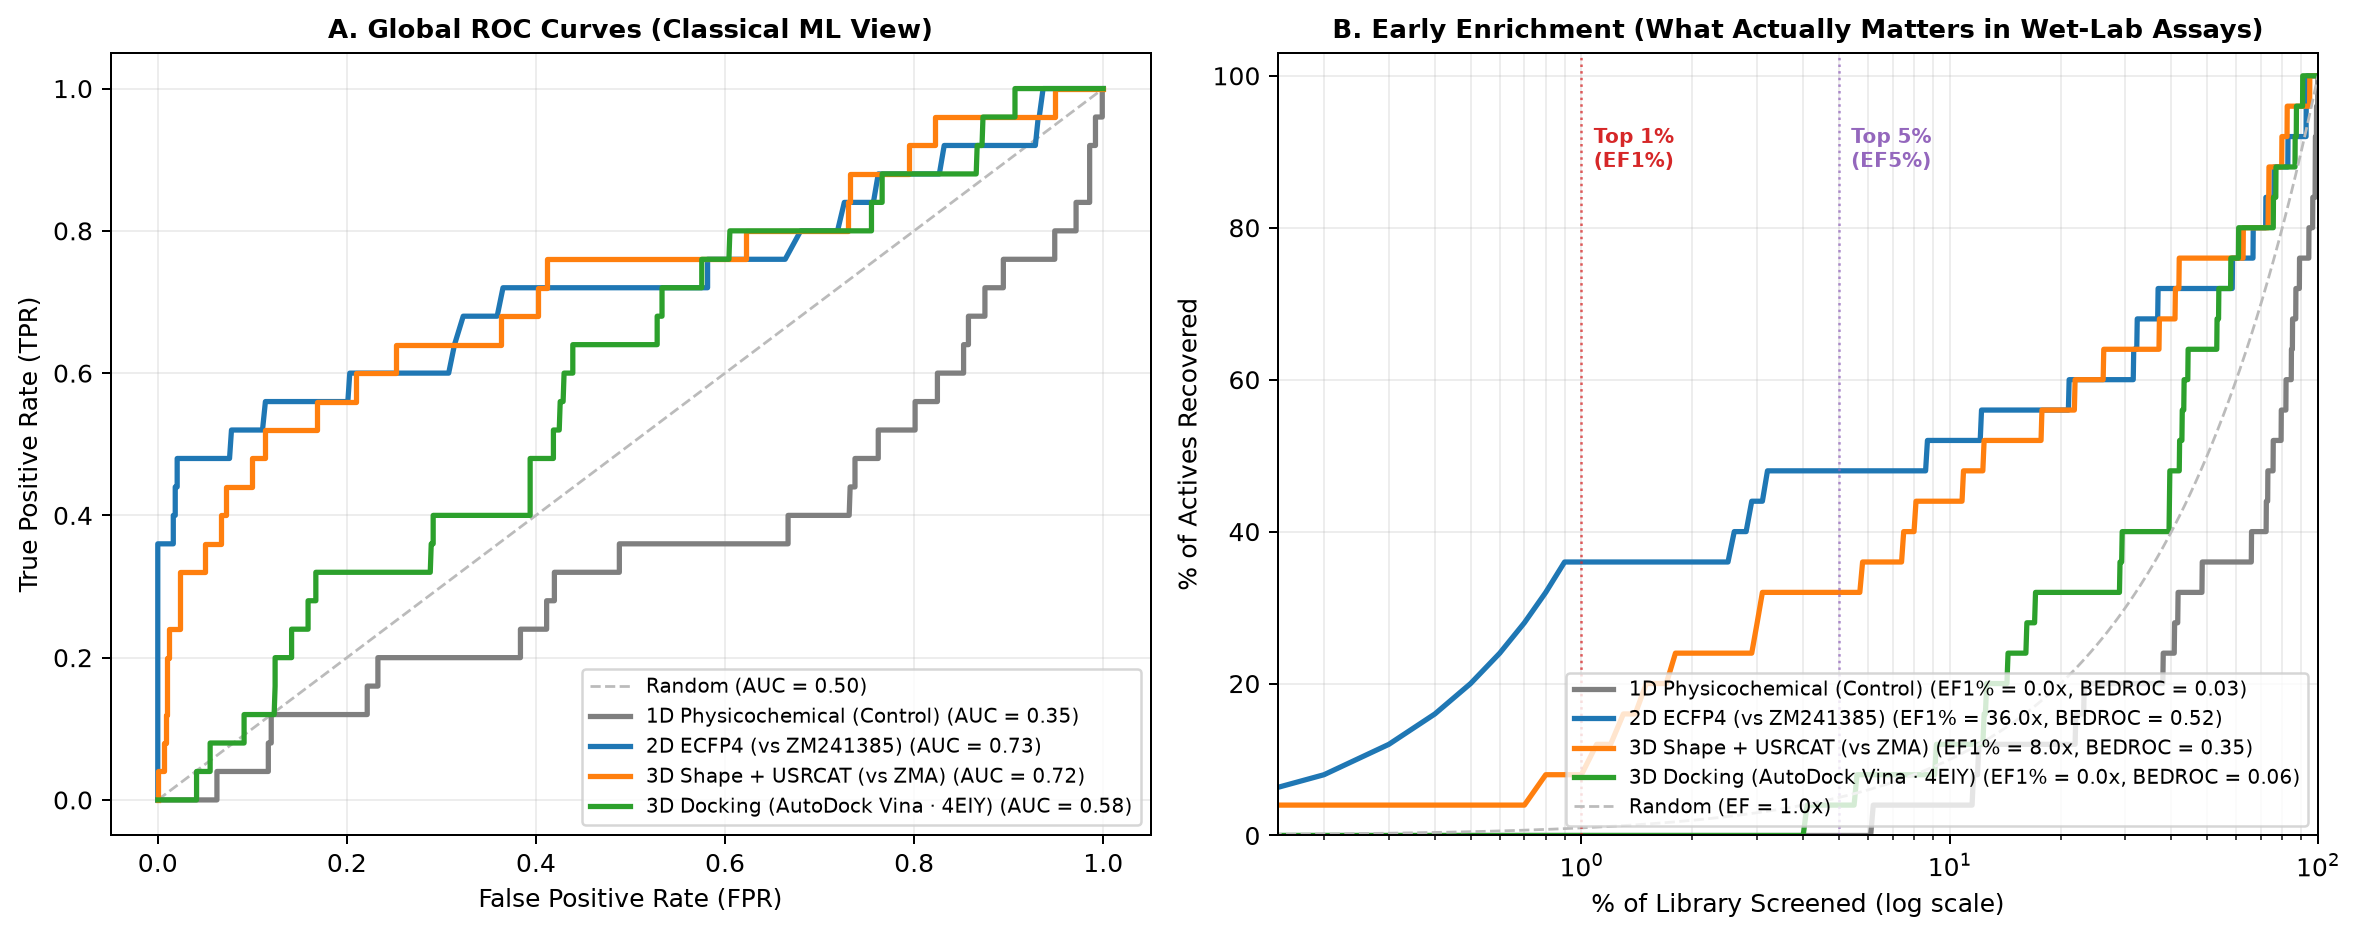

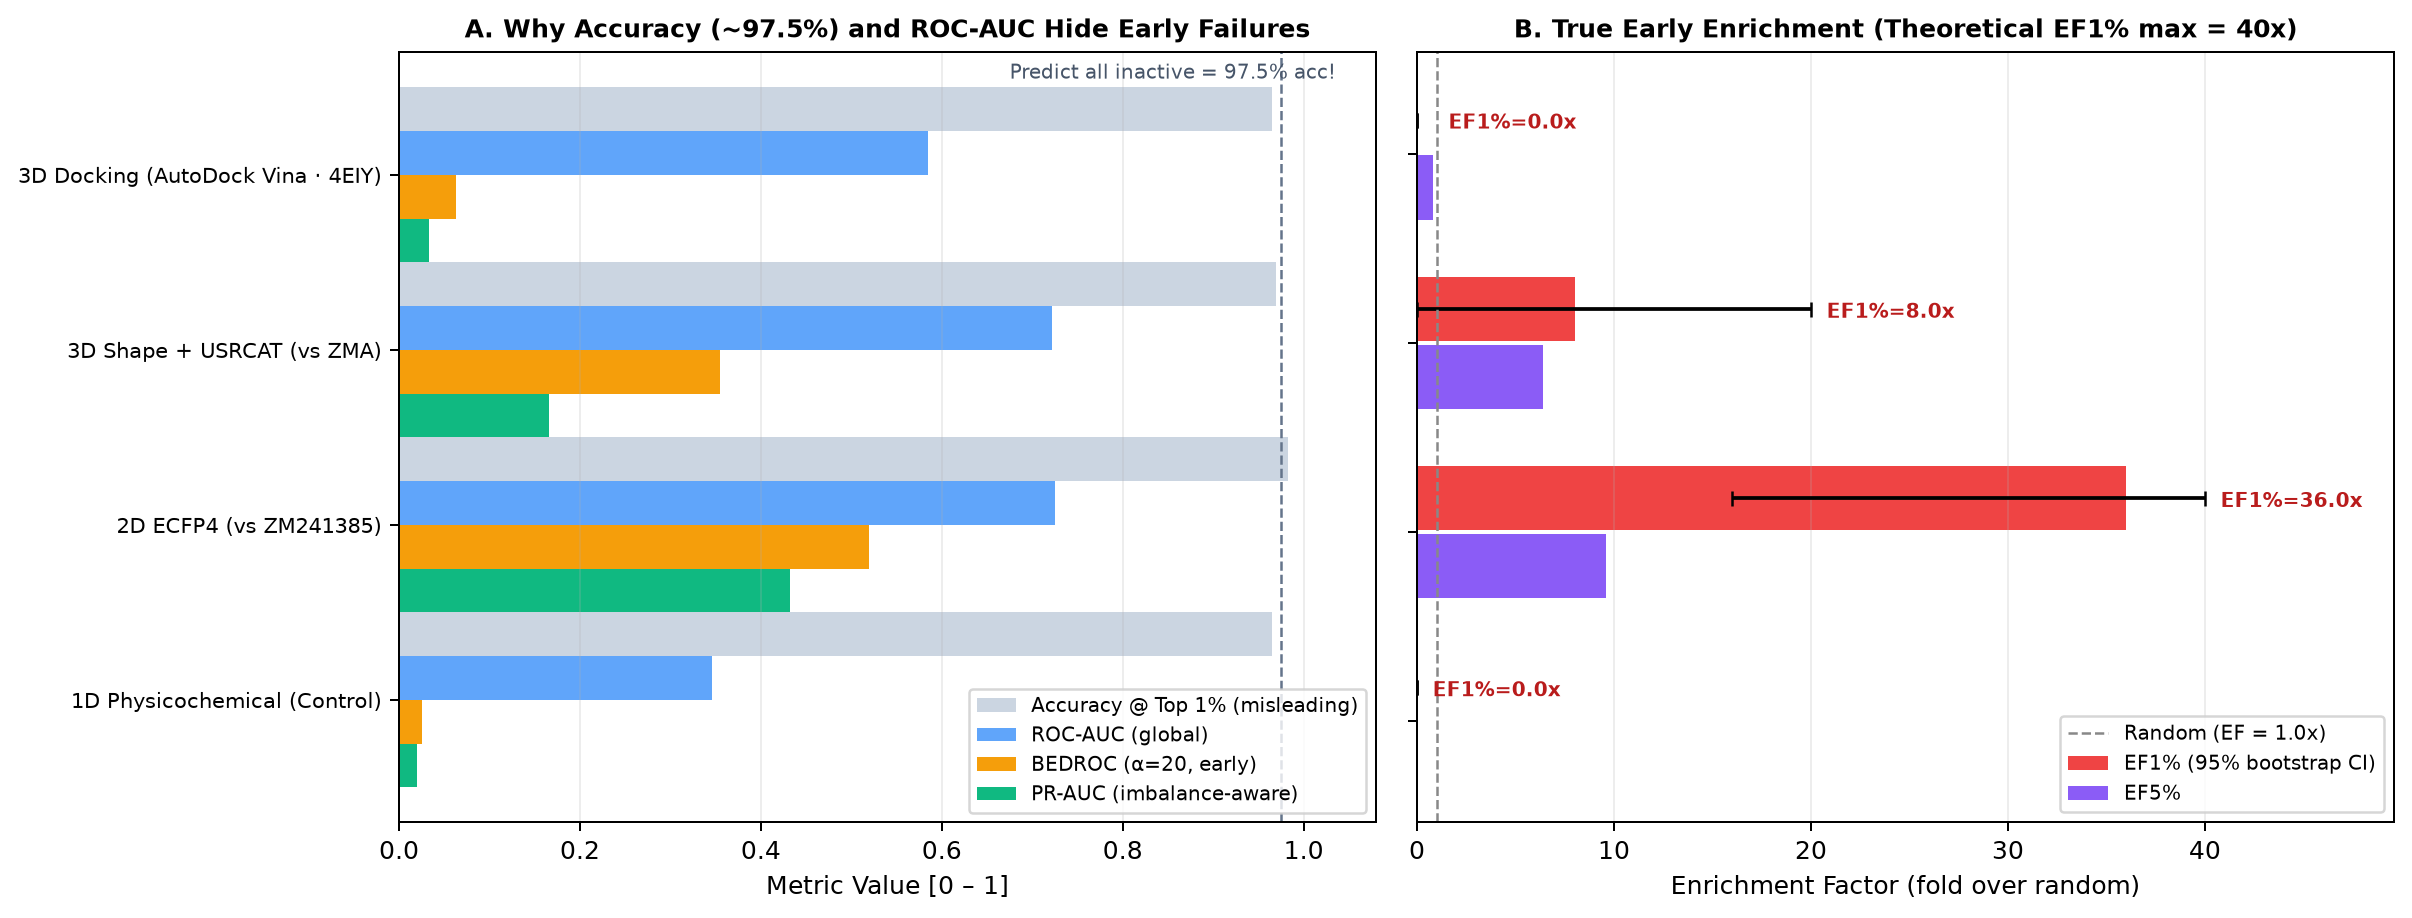

In [4]:
metrics_df = pd.DataFrame(summary["benchmark_metrics"])
display(
    metrics_df[
        [
            "method",
            "ef1",
            "ef5",
            "bedroc_20",
            "roc_auc",
            "pr_auc",
            "accuracy_top1pct",
            "naive_all_inactive_accuracy",
        ]
    ].round(3)
)

print("\nStrict scaffold-hop subset (excluding close analogues with ECFP4 >= 0.35 to ZM241385):")
hop = summary["scaffold_hop_no_zma_analogues"]
display(
    pd.DataFrame([hop["2d_ecfp4"], hop["autodock_vina"]])[
        ["method", "n_actives", "ef1", "ef5", "bedroc_20", "roc_auc", "pr_auc"]
    ].round(3)
)

print("\nSupervised 2D generalization on experimental CHEMBL251 (Random Split vs Murcko Scaffold Split):")
ms = summary["murcko_split_experimental_chembl"]
display(
    pd.DataFrame([ms["random_split"], ms["murcko_scaffold_split"]])[
        ["method", "ef1", "ef5", "bedroc_20", "roc_auc", "pr_auc"]
    ].round(3)
)

display(Image(filename=str(FIGS / "benchmark_roc_and_enrichment.png")))
display(Image(filename=str(FIGS / "metrics_accuracy_vs_enrichment.png")))

## 4. Screening Score vs. Experimental Binding Affinity ($pK_i$)

We evaluate **60 curated `CHEMBL251` $K_i$ ligands** spanning > 5 orders of magnitude ($pK_i \in [4.0,\; 11.0]$, from micromolar methylxanthines to sub-nanomolar clinical antagonists), quantifying Pearson $r$, $R^2$, and Spearman $\rho$.

,pearson_r,pearson_r2,pearson_p,spearman_rho,spearman_p
"AutoDock Vina (-ΔG, kcal/mol)",0.161,0.026,0.2186,0.222,0.0888
2D ECFP4 Tanimoto (vs ZM241385),0.246,0.060,0.0583,0.226,0.0826
3D Shape + USRCAT (vs ZM241385),0.524,0.274,0.0000,0.500,0.0000


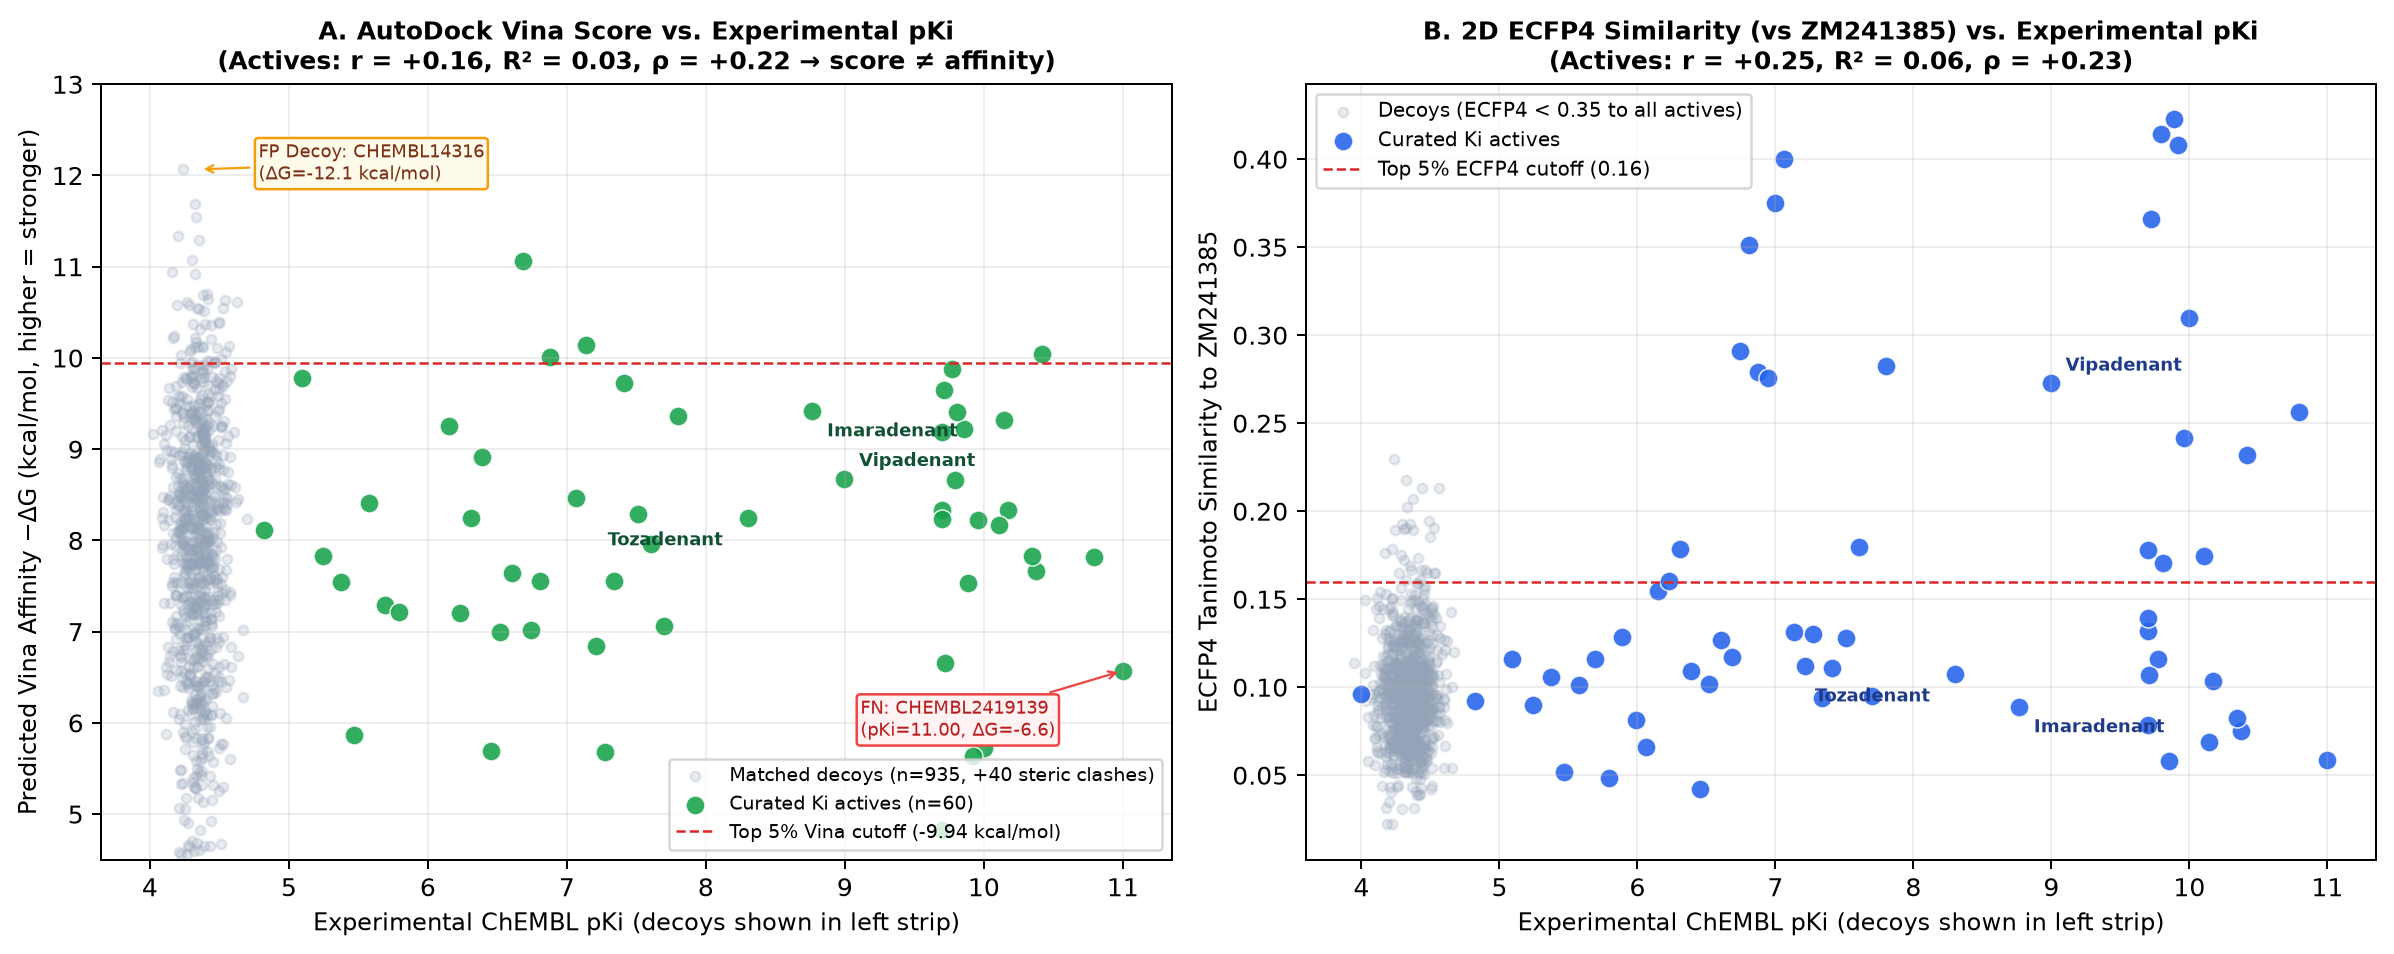

In [5]:
corr_df = pd.DataFrame(summary["affinity_correlation_wide_n60"]).T
display(corr_df)
display(Image(filename=str(FIGS / "affinity_vs_score_scatter.png")))